<a href="https://colab.research.google.com/github/EliavR2005/AutoKnowledge-AI/blob/main/AutoKnowledge_Clasificacion_Modelos.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd

archivo = "AutoKnowledge_100_Reportes.xlsx"

df = pd.read_excel(
    archivo,
    sheet_name="100 reportes",
    header=5
)

display(df.head())

,ID,REPORTE EMPRESARIAL
0,REP-001,Se deben actualizar los registros de afiliació...
1,REP-002,Un empleado solicita reembolso de gastos de vi...
2,REP-003,Recursos Humanos debe procesar la baja laboral...
3,REP-004,Las tabletas utilizadas por los repartidores n...
4,REP-005,Un colaborador no puede iniciar sesión en su c...


In [ ]:
# Mostrar los nombres de las columnas del conjunto de datos
print("Columnas del conjunto de datos:")
print(df.columns.tolist())

# Contar la cantidad total de reportes cargados
print("\nCantidad de registros:")
print(len(df))

# Identificar cuántos valores vacíos existen en cada columna
print("\nRegistros vacíos:")
print(df.isnull().sum())

Columnas del conjunto de datos:
['ID', 'REPORTE EMPRESARIAL']

Cantidad de registros:
100

Registros vacíos:
ID                     0
REPORTE EMPRESARIAL    0
dtype: int64


In [ ]:
# Importar pandas para trabajar con los datos
import pandas as pd

# Cargar el Excel que contiene los 100 reportes clasificados
archivo = "AutoKnowledge_100_Reportes_Clasificados.xlsx"
df = pd.read_excel(archivo)

# Mostrar los primeros cinco registros
display(df.head())

,ID,REPORTE EMPRESARIAL,CATEGORIA
0,REP-001,Se deben actualizar los registros de afiliació...,Recursos Humanos
1,REP-002,Un empleado solicita reembolso de gastos de vi...,Finanzas
2,REP-003,Recursos Humanos debe procesar la baja laboral...,Recursos Humanos
3,REP-004,Las tabletas utilizadas por los repartidores n...,Soporte Técnico
4,REP-005,Un colaborador no puede iniciar sesión en su c...,Soporte Técnico


In [ ]:
# Mostrar las columnas disponibles
print("Columnas:")
print(df.columns.tolist())

# Comprobar la cantidad de reportes
print("\nTotal de reportes:")
print(len(df))

# Revisar si existen valores vacíos
print("\nValores vacíos:")
print(df.isnull().sum())

# Contar los reportes de cada categoría
print("\nCantidad por categoría:")
print(df["CATEGORIA"].value_counts())

Columnas:
['ID', 'REPORTE EMPRESARIAL', 'CATEGORIA']

Total de reportes:
100

Valores vacíos:
ID                     0
REPORTE EMPRESARIAL    0
CATEGORIA              0
dtype: int64

Cantidad por categoría:
CATEGORIA
Soporte Técnico     34
Recursos Humanos    33
Finanzas            33
Name: count, dtype: int64


In [ ]:
# Importar la función para dividir los datos 80/20
from sklearn.model_selection import train_test_split

# Separar el texto de los reportes y sus categorías
X = df["REPORTE EMPRESARIAL"]
y = df["CATEGORIA"]

# Dividir los datos en entrenamiento y prueba
# stratify conserva la proporción de las categorías
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Mostrar la cantidad de registros de cada grupo
print("Reportes para entrenamiento:", len(X_train))
print("Reportes para prueba:", len(X_test))

Reportes para entrenamiento: 80
Reportes para prueba: 20


In [ ]:
# Importar la herramienta para convertir texto en valores numéricos
from sklearn.feature_extraction.text import TfidfVectorizer

# Crear el vectorizador TF-IDF
vectorizador = TfidfVectorizer()

# Aprender el vocabulario únicamente con los datos de entrenamiento
X_train_tfidf = vectorizador.fit_transform(X_train)

# Transformar los datos de prueba usando el mismo vocabulario
X_test_tfidf = vectorizador.transform(X_test)

# Mostrar las dimensiones de las matrices generadas
print("Dimensiones de entrenamiento:", X_train_tfidf.shape)
print("Dimensiones de prueba:", X_test_tfidf.shape)

Dimensiones de entrenamiento: (80, 471)
Dimensiones de prueba: (20, 471)


In [ ]:
# Importar los algoritmos de clasificación
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC

# Crear el modelo Naive Bayes
modelo_nb = MultinomialNB()

# Crear el modelo SVM
modelo_svm = LinearSVC(random_state=42)

# Entrenar Naive Bayes con los datos de entrenamiento
modelo_nb.fit(X_train_tfidf, y_train)

# Entrenar SVM con los mismos datos de entrenamiento
modelo_svm.fit(X_train_tfidf, y_train)

# Confirmar que ambos modelos terminaron de entrenarse
print("Los modelos Naive Bayes y SVM fueron entrenados correctamente.")

Los modelos Naive Bayes y SVM fueron entrenados correctamente.


In [ ]:
# Obtener las predicciones de Naive Bayes
predicciones_nb = modelo_nb.predict(X_test_tfidf)

# Obtener las predicciones de SVM
predicciones_svm = modelo_svm.predict(X_test_tfidf)

# Mostrar las predicciones de ambos modelos
print("PREDICCIONES DE NAIVE BAYES:")
print(predicciones_nb)

print("\nPREDICCIONES DE SVM:")
print(predicciones_svm)

PREDICCIONES DE NAIVE BAYES:
['Finanzas' 'Soporte Técnico' 'Finanzas' 'Soporte Técnico'
 'Recursos Humanos' 'Soporte Técnico' 'Finanzas' 'Finanzas'
 'Soporte Técnico' 'Finanzas' 'Soporte Técnico' 'Finanzas'
 'Soporte Técnico' 'Finanzas' 'Recursos Humanos' 'Soporte Técnico'
 'Recursos Humanos' 'Recursos Humanos' 'Recursos Humanos' 'Finanzas']

PREDICCIONES DE SVM:
['Finanzas' 'Soporte Técnico' 'Finanzas' 'Soporte Técnico'
 'Recursos Humanos' 'Soporte Técnico' 'Finanzas' 'Finanzas'
 'Soporte Técnico' 'Finanzas' 'Soporte Técnico' 'Finanzas'
 'Soporte Técnico' 'Finanzas' 'Recursos Humanos' 'Soporte Técnico'
 'Recursos Humanos' 'Recursos Humanos' 'Recursos Humanos' 'Finanzas']


In [ ]:
# Crear una tabla para comparar las categorías reales y las predichas
comparacion = pd.DataFrame({
    "CATEGORIA_REAL": y_test.values,
    "PREDICCION_NAIVE_BAYES": predicciones_nb,
    "PREDICCION_SVM": predicciones_svm
})

# Agregar una columna para identificar si cada modelo acertó
comparacion["NB_CORRECTO"] = (
    comparacion["CATEGORIA_REAL"] == comparacion["PREDICCION_NAIVE_BAYES"]
)

comparacion["SVM_CORRECTO"] = (
    comparacion["CATEGORIA_REAL"] == comparacion["PREDICCION_SVM"]
)

# Mostrar los resultados de los 20 reportes
display(comparacion)

,CATEGORIA_REAL,PREDICCION_NAIVE_BAYES,PREDICCION_SVM,NB_CORRECTO,SVM_CORRECTO
0,Finanzas,Finanzas,Finanzas,True,True
1,Soporte Técnico,Soporte Técnico,Soporte Técnico,True,True
2,Finanzas,Finanzas,Finanzas,True,True
3,Finanzas,Soporte Técnico,Soporte Técnico,False,False
4,Recursos Humanos,Recursos Humanos,Recursos Humanos,True,True
5,Soporte Técnico,Soporte Técnico,Soporte Técnico,True,True
6,Finanzas,Finanzas,Finanzas,True,True
7,Recursos Humanos,Finanzas,Finanzas,False,False
8,Soporte Técnico,Soporte Técnico,Soporte Técnico,True,True
9,Finanzas,Finanzas,Finanzas,True,True


In [ ]:
# Importar las métricas de evaluación
from sklearn.metrics import accuracy_score, classification_report

# Calcular Accuracy de Naive Bayes
accuracy_nb = accuracy_score(y_test, predicciones_nb)

# Calcular Accuracy de SVM
accuracy_svm = accuracy_score(y_test, predicciones_svm)

# Mostrar Accuracy de ambos modelos
print("ACCURACY")
print("Naive Bayes:", accuracy_nb)
print("SVM:", accuracy_svm)

# Mostrar Precision, Recall y F1-score de Naive Bayes
print("\nRESULTADOS DE NAIVE BAYES")
print(classification_report(y_test, predicciones_nb, zero_division=0))

# Mostrar Precision, Recall y F1-score de SVM
print("\nRESULTADOS DE SVM")
print(classification_report(y_test, predicciones_svm, zero_division=0))

ACCURACY
Naive Bayes: 0.8
SVM: 0.8

RESULTADOS DE NAIVE BAYES
                  precision    recall  f1-score   support

        Finanzas       0.75      0.86      0.80         7
Recursos Humanos       0.80      0.67      0.73         6
 Soporte Técnico       0.86      0.86      0.86         7

        accuracy                           0.80        20
       macro avg       0.80      0.79      0.79        20
    weighted avg       0.80      0.80      0.80        20


RESULTADOS DE SVM
                  precision    recall  f1-score   support

        Finanzas       0.75      0.86      0.80         7
Recursos Humanos       0.80      0.67      0.73         6
 Soporte Técnico       0.86      0.86      0.86         7

        accuracy                           0.80        20
       macro avg       0.80      0.79      0.79        20
    weighted avg       0.80      0.80      0.80        20



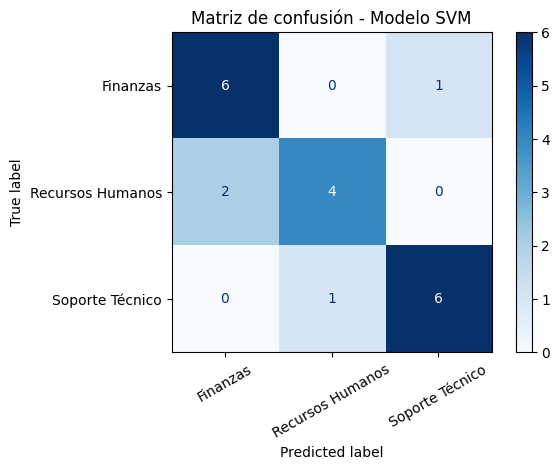


========== MATRIZ DE CONFUSIÓN EN TEXTO ==========
Filas = Categoría real | Columnas = Categoría predicha

                  Finanzas  Recursos Humanos  Soporte Técnico
Finanzas                 6                 0                1
Recursos Humanos         2                 4                0
Soporte Técnico          0                 1                6

========== RESUMEN DE RESULTADOS ==========
Total de reportes evaluados: 20
Clasificaciones correctas: 16
Clasificaciones incorrectas: 4
Porcentaje de aciertos: 80.00%
Porcentaje de errores: 20.00%

========== REPORTES MAL CLASIFICADOS ==========
     ID   CATEGORIA_REAL CATEGORIA_PREDICHA                                                                           REPORTE_EMPRESARIAL
REP-020         Finanzas    Soporte Técnico Se registrará un ajuste contable por una diferencia detectada en la valuación del inventario.
REP-086 Recursos Humanos           Finanzas      Se debe completar el proceso de inducción para tres personas que ingres

In [ ]:
# Importar las herramientas para calcular y visualizar la matriz de confusión
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
import pandas as pd

# Definir el orden de las categorías
categorias = ["Finanzas", "Recursos Humanos", "Soporte Técnico"]

# Calcular la matriz de confusión del modelo SVM
matriz_svm = confusion_matrix(
    y_test,
    predicciones_svm,
    labels=categorias
)

# Mostrar la matriz como imagen
visualizacion = ConfusionMatrixDisplay(
    confusion_matrix=matriz_svm,
    display_labels=categorias
)

visualizacion.plot(cmap="Blues", xticks_rotation=30)
plt.title("Matriz de confusión - Modelo SVM")
plt.tight_layout()
plt.show()

# Mostrar los mismos resultados en texto para poder analizarlos
print("\n========== MATRIZ DE CONFUSIÓN EN TEXTO ==========")
print("Filas = Categoría real | Columnas = Categoría predicha")
print()

matriz_texto = pd.DataFrame(
    matriz_svm,
    index=categorias,
    columns=categorias
)

print(matriz_texto.to_string())

# Calcular y mostrar los aciertos y errores
aciertos = matriz_svm.trace()
total = matriz_svm.sum()
errores = total - aciertos

print("\n========== RESUMEN DE RESULTADOS ==========")
print(f"Total de reportes evaluados: {total}")
print(f"Clasificaciones correctas: {aciertos}")
print(f"Clasificaciones incorrectas: {errores}")
print(f"Porcentaje de aciertos: {aciertos / total:.2%}")
print(f"Porcentaje de errores: {errores / total:.2%}")

# Mostrar los reportes que el modelo clasificó incorrectamente
errores_svm = pd.DataFrame({
    "ID": df.loc[X_test.index, "ID"].values,
    "CATEGORIA_REAL": y_test.values,
    "CATEGORIA_PREDICHA": predicciones_svm,
    "REPORTE_EMPRESARIAL": X_test.values
})

errores_svm = errores_svm[
    errores_svm["CATEGORIA_REAL"] != errores_svm["CATEGORIA_PREDICHA"]
]

print("\n========== REPORTES MAL CLASIFICADOS ==========")
print(errores_svm.to_string(index=False))

In [ ]:
# Crear una tabla con los reportes reales y las predicciones de SVM
errores_svm = pd.DataFrame({
    "ID": df.loc[X_test.index, "ID"].values,
    "CATEGORIA_REAL": y_test.values,
    "CATEGORIA_PREDICHA": predicciones_svm,
    "REPORTE_EMPRESARIAL": X_test.values
})

# Conservar únicamente los reportes que fueron clasificados incorrectamente
errores_svm = errores_svm[
    errores_svm["CATEGORIA_REAL"] != errores_svm["CATEGORIA_PREDICHA"]
]

# Mostrar los errores encontrados
print("Cantidad de errores:", len(errores_svm))

display(errores_svm)

Cantidad de errores: 4


,ID,CATEGORIA_REAL,CATEGORIA_PREDICHA,REPORTE_EMPRESARIAL
3,REP-020,Finanzas,Soporte Técnico,Se registrará un ajuste contable por una difer...
7,REP-086,Recursos Humanos,Finanzas,Se debe completar el proceso de inducción para...
11,REP-089,Recursos Humanos,Finanzas,Una colaboradora solicita autorización para to...
17,REP-045,Soporte Técnico,Recursos Humanos,Un empleado recibe un mensaje de autenticación...


8. Prueba con documentos nuevos.

In [ ]:
# Importar pandas para crear una tabla con los nuevos reportes
import pandas as pd

# Crear cinco reportes que no pertenecen al conjunto original de 100 documentos
reportes_nuevos = pd.DataFrame({
    "ID": ["NUEVO-001", "NUEVO-002", "NUEVO-003", "NUEVO-004", "NUEVO-005"],

    "REPORTE_EMPRESARIAL": [
        "El departamento contable necesita revisar las facturas pendientes de pago a los proveedores.",
        "Se solicita actualizar el expediente laboral de un trabajador debido a un cambio de puesto.",
        "La computadora del área de ventas presenta fallas al iniciar el sistema operativo.",
        "El área financiera realizará una revisión del presupuesto asignado para el siguiente trimestre.",
        "Un colaborador solicita información sobre los días de permiso disponibles durante el año."
    ],

    # Estas son las categorías esperadas según la revisión humana
    "CATEGORIA_ESPERADA": [
        "Finanzas",
        "Recursos Humanos",
        "Soporte Técnico",
        "Finanzas",
        "Recursos Humanos"
    ]
})

# Mostrar los cinco reportes nuevos
print("========== CINCO REPORTES NUEVOS ==========")
display(reportes_nuevos)

========== CINCO REPORTES NUEVOS ==========


,ID,REPORTE_EMPRESARIAL,CATEGORIA_ESPERADA
0,NUEVO-001,El departamento contable necesita revisar las ...,Finanzas
1,NUEVO-002,Se solicita actualizar el expediente laboral d...,Recursos Humanos
2,NUEVO-003,La computadora del área de ventas presenta fal...,Soporte Técnico
3,NUEVO-004,El área financiera realizará una revisión del ...,Finanzas
4,NUEVO-005,Un colaborador solicita información sobre los ...,Recursos Humanos


In [ ]:
# Obtener los textos de los cinco reportes nuevos
X_nuevos = reportes_nuevos["REPORTE_EMPRESARIAL"]

# Transformar los textos utilizando el mismo vectorizador TF-IDF del entrenamiento
# Solo usamos transform(), porque el vectorizador ya fue entrenado anteriormente
X_nuevos_tfidf = vectorizador.transform(X_nuevos)

# Clasificar los cinco reportes utilizando el modelo SVM entrenado
predicciones_nuevas = modelo_svm.predict(X_nuevos_tfidf)

# Agregar las categorías predichas a la tabla original
reportes_nuevos["CATEGORIA_PREDICHA"] = predicciones_nuevas

# Comparar la categoría esperada con la categoría predicha
reportes_nuevos["RESULTADO"] = (
    reportes_nuevos["CATEGORIA_ESPERADA"] ==
    reportes_nuevos["CATEGORIA_PREDICHA"]
).map({
    True: "Correcto",
    False: "Incorrecto"
})

# Mostrar los resultados de clasificación
print("========== RESULTADOS DE LOS REPORTES NUEVOS ==========")
display(reportes_nuevos)

# Calcular cuántos reportes fueron clasificados correctamente
aciertos_nuevos = (
    reportes_nuevos["CATEGORIA_ESPERADA"] ==
    reportes_nuevos["CATEGORIA_PREDICHA"]
).sum()

total_nuevos = len(reportes_nuevos)

# Mostrar el resumen de resultados
print("\n========== RESUMEN DE EVALUACIÓN ==========")
print(f"Total de reportes nuevos: {total_nuevos}")
print(f"Clasificaciones correctas: {aciertos_nuevos}")
print(f"Clasificaciones incorrectas: {total_nuevos - aciertos_nuevos}")
print(f"Porcentaje de aciertos: {aciertos_nuevos / total_nuevos:.2%}")

========== RESULTADOS DE LOS REPORTES NUEVOS ==========


,ID,REPORTE_EMPRESARIAL,CATEGORIA_ESPERADA,CATEGORIA_PREDICHA,RESULTADO
0,NUEVO-001,El departamento contable necesita revisar las ...,Finanzas,Finanzas,Correcto
1,NUEVO-002,Se solicita actualizar el expediente laboral d...,Recursos Humanos,Recursos Humanos,Correcto
2,NUEVO-003,La computadora del área de ventas presenta fal...,Soporte Técnico,Soporte Técnico,Correcto
3,NUEVO-004,El área financiera realizará una revisión del ...,Finanzas,Finanzas,Correcto
4,NUEVO-005,Un colaborador solicita información sobre los ...,Recursos Humanos,Recursos Humanos,Correcto



========== RESUMEN DE EVALUACIÓN ==========
Total de reportes nuevos: 5
Clasificaciones correctas: 5
Clasificaciones incorrectas: 0
Porcentaje de aciertos: 100.00%


#11. Generación de embeddings

In [ ]:
# Instalar la biblioteca necesaria para generar embeddings
!pip install -q sentence-transformers

# Importar la herramienta para cargar modelos de embeddings
from sentence_transformers import SentenceTransformer

# Cargar el modelo multilingüe compatible con español
nombre_modelo = "sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2"
modelo_embeddings = SentenceTransformer(nombre_modelo)

# Confirmar que el modelo se cargó correctamente
print("Modelo de embeddings cargado correctamente.")
print("Nombre del modelo:", nombre_modelo)
print("Dimensiones de cada embedding:", modelo_embeddings.get_sentence_embedding_dimension())

modules.json:   0%|          | 0.00/229 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/122 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/3.89k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/645 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  471MB            

... (5 outputs left out)

special_tokens_map.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Modelo de embeddings cargado correctamente.
Nombre del modelo: sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2
Dimensiones de cada embedding: 384


/tmp/ipykernel_1352/2165308188.py:14: FutureWarning: The `get_sentence_embedding_dimension` method has been renamed to `get_embedding_dimension`.
  print("Dimensiones de cada embedding:", modelo_embeddings.get_sentence_embedding_dimension())


In [ ]:
# Obtener los textos de los 100 reportes empresariales
textos_reportes = df["REPORTE EMPRESARIAL"].astype(str).tolist()

# Generar los embeddings utilizando el modelo multilingüe
embeddings = modelo_embeddings.encode(
    textos_reportes,
    show_progress_bar=True,
    convert_to_numpy=True
)

# Mostrar las dimensiones de la matriz de embeddings
print("========== RESULTADOS DE LOS EMBEDDINGS ==========")
print("Total de reportes procesados:", len(textos_reportes))
print("Dimensiones de la matriz:", embeddings.shape)
print("Dimensiones por documento:", embeddings.shape[1])

# Verificar que todos los embeddings tengan valores numéricos
print("\n¿Todos los valores son numéricos?:", pd.notna(embeddings).all())
print("¿Existen valores infinitos?:", __import__("numpy").isinf(embeddings).any())

# Mostrar una pequeña parte del primer embedding
print("\nPrimeros 10 valores del embedding del primer reporte:")
print(embeddings[0][:10])

Batches:   0%|          | 0/4 [00:00<?, ?it/s]

========== RESULTADOS DE LOS EMBEDDINGS ==========
Total de reportes procesados: 100
Dimensiones de la matriz: (100, 384)
Dimensiones por documento: 384

¿Todos los valores son numéricos?: True
¿Existen valores infinitos?: False

Primeros 10 valores del embedding del primer reporte:
[-0.25116006  0.03199416 -0.2321421  -0.02470543 -0.11675061  0.28429157
 -0.1894738  -0.18917175 -0.09868158  0.01152094]


In [ ]:
# Importar NumPy para realizar verificaciones numéricas
import numpy as np

# Comprobar que cada reporte tenga un embedding diferente
embeddings_unicos = np.unique(embeddings, axis=0)

# Crear una tabla para relacionar cada documento con su embedding
tabla_embeddings = pd.DataFrame({
    "ID": df["ID"],
    "CATEGORIA": df["CATEGORIA"],
    "DIMENSIONES": [len(vector) for vector in embeddings],
    "VALORES_NUMERICOS": [
        np.isfinite(vector).all() for vector in embeddings
    ]
})

# Mostrar los primeros cinco documentos y sus verificaciones
print("========== VERIFICACIÓN DE EMBEDDINGS ==========")
display(tabla_embeddings.head())

# Mostrar el resumen de las comprobaciones
print("\nTotal de documentos:", len(tabla_embeddings))
print("Vectores únicos:", len(embeddings_unicos))
print("Documentos con 384 dimensiones:",
      (tabla_embeddings["DIMENSIONES"] == 384).sum())
print("Documentos con valores numéricos válidos:",
      tabla_embeddings["VALORES_NUMERICOS"].sum())

========== VERIFICACIÓN DE EMBEDDINGS ==========


,ID,CATEGORIA,DIMENSIONES,VALORES_NUMERICOS
0,REP-001,Recursos Humanos,384,True
1,REP-002,Finanzas,384,True
2,REP-003,Recursos Humanos,384,True
3,REP-004,Soporte Técnico,384,True
4,REP-005,Soporte Técnico,384,True



Total de documentos: 100
Vectores únicos: 100
Documentos con 384 dimensiones: 100
Documentos con valores numéricos válidos: 100


In [ ]:
# Importar las herramientas necesarias
from sklearn.metrics.pairwise import cosine_similarity
import pandas as pd

# Solicitar al usuario que escriba su consulta
consulta = input("Escribe tu consulta para buscar reportes: ")

# Validar que la consulta no esté vacía
if consulta.strip():

    # Convertir la consulta en un embedding
    embedding_consulta = modelo_embeddings.encode(
        [consulta],
        convert_to_numpy=True
    )

    # Comparar la consulta con los embeddings almacenados
    similitudes = cosine_similarity(
        embedding_consulta,
        embeddings
    )[0]

    # Crear una tabla con los documentos y sus similitudes
    resultados_busqueda = df[
        ["ID", "CATEGORIA", "REPORTE EMPRESARIAL"]
    ].copy()

    resultados_busqueda["SIMILITUD"] = similitudes

    # Recuperar los tres documentos más similares
    resultados_top3 = resultados_busqueda.sort_values(
        by="SIMILITUD",
        ascending=False
    ).head(3).reset_index(drop=True)

    # Mostrar los resultados
    print("\n========== BÚSQUEDA SEMÁNTICA ==========")
    print("Consulta ingresada:", consulta)
    print("\n========== TRES REPORTES MÁS RELEVANTES ==========")

    display(resultados_top3)

    # Mostrar los resultados como texto
    print("\n========== RESULTADOS EN TEXTO ==========")
    print(resultados_top3.to_string(index=False))

else:
    print("Error: debes ingresar una consulta.")

Escribe tu consulta para buscar reportes: No puedo conectarme a internet

========== BÚSQUEDA SEMÁNTICA ==========
Consulta ingresada: No puedo conectarme a internet

========== TRES REPORTES MÁS RELEVANTES ==========


,ID,CATEGORIA,REPORTE EMPRESARIAL,SIMILITUD
0,REP-053,Soporte Técnico,El servidor principal dejó de responder y los ...,0.447069
1,REP-015,Soporte Técnico,El firewall bloquea el acceso autorizado de un...,0.417940
2,REP-042,Soporte Técnico,La red inalámbrica del almacén pierde señal en...,0.399621



========== RESULTADOS EN TEXTO ==========
     ID       CATEGORIA                                                                                 REPORTE EMPRESARIAL  SIMILITUD
REP-053 Soporte Técnico El servidor principal dejó de responder y los usuarios no pueden acceder al sistema de inventarios.   0.447069
REP-015 Soporte Técnico               El firewall bloquea el acceso autorizado de una sucursal a la plataforma corporativa.   0.417940
REP-042 Soporte Técnico          La red inalámbrica del almacén pierde señal en los pasillos donde se realizan los conteos.   0.399621
